# 6. Model Comparison

This notebook consolidates and compares the results from the classical machine-learning, neural-network, and transformer experiments.

The comparison uses the saved validation results produced in the preceding notebooks. No models are retrained, and the official test set is not accessed. All comparisons therefore remain within the development stage of the project.

The analysis considers predictive performance alongside computational efficiency. In particular, it examines macro F1, accuracy, weighted F1, training time, inference time, throughput, model artifact size, and per-class performance.

An important consideration is that the experiments do not all use the same text representation. Classical models were evaluated using both complete messages and extracted message bodies, whereas the neural-network and transformer experiments used message bodies. The comparison therefore distinguishes the overall best-performing configurations from comparisons in which the text representation is held constant.

The primary model-selection metric is macro F1. This metric gives equal importance to each class and is therefore useful when evaluating performance across the twenty newsgroup categories.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "results/logs/model_comparison.json").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

COMPARISON_PATH = PROJECT_ROOT / "results/logs/model_comparison.json"
METRICS_PATH = PROJECT_ROOT / "results/metrics/model_comparison.csv"

assert COMPARISON_PATH.is_file(), (
    f"Comparison results not found: {COMPARISON_PATH}. "
    "Run scripts/evaluate_models.py from the project root first."
)

assert METRICS_PATH.is_file(), (
    f"Comparison metrics not found: {METRICS_PATH}. "
    "Run scripts/evaluate_models.py from the project root first."
)

print(f"Project root: {PROJECT_ROOT}")
print(f"Detailed results: {COMPARISON_PATH}")
print(f"Metrics table: {METRICS_PATH}")

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Detailed results: /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/model_comparison.json
Metrics table: /home/nkululekocyrilcele/projects/topicsense-nlp/results/metrics/model_comparison.csv


## 6.1 Loading and Validating the Comparison Results

The consolidated results are loaded from the JSON and CSV files generated by the model-comparison script.

The JSON file contains the detailed experiment records, including performance metrics and additional evaluation information. The CSV file provides a tabular representation suitable for analysis and visualisation.

Before proceeding, the notebook verifies that all sixteen expected experiment runs are present and that the comparison records confirm that the official test data was excluded.

In [2]:
with COMPARISON_PATH.open("r", encoding="utf-8") as file:
    comparison = json.load(file)

comparison_df = pd.read_csv(METRICS_PATH)

metadata = comparison["metadata"]
runs = comparison["runs"]

assert len(runs) == 16, (
    f"Expected 16 experiment runs, found {len(runs)}."
)

assert metadata["experiment_count"] == 16

assert metadata["test_data_used"] is False, (
    "The consolidated comparison indicates that test data was used."
)

assert len(comparison_df) == 16

print("Comparison validation passed.")
print(f"Experiment runs: {len(runs)}")
print(f"Dataset: {metadata['dataset']}")
print(f"Training documents: {metadata['training_documents']:,}")
print(f"Validation documents: {metadata['validation_documents']:,}")
print(f"Random seed: {metadata['random_seed']}")
print(f"Official test data used: {metadata['test_data_used']}")

Comparison validation passed.
Experiment runs: 16
Dataset: 20newsgroups
Training documents: 9,051
Validation documents: 2,263
Random seed: 42
Official test data used: False


### Interpreting the Comparison Metadata

The comparison contains sixteen experiment runs: twelve classical machine-learning configurations, two neural-network models, and two transformer-based approaches.

All experiments use the same development training and validation partitions, comprising 9,051 training documents and 2,263 validation documents. The experiments also share the same random seed.

The official test set was not used during model training, hyperparameter selection, or this comparison. This preserves the distinction between development-stage model selection and the final evaluation that will be conducted later.

The results are therefore suitable for comparing the current validation performance of the evaluated configurations, but they should not yet be presented as final test-set performance.

## 6.2 Overall Model Ranking

The first comparison ranks all sixteen experiment configurations by validation macro F1.

Accuracy, macro precision, macro recall, and weighted F1 are retained alongside macro F1 to provide a broader view of model performance.

The ranking is based on individual experiment configurations rather than model families. This is important because the classical experiments include different combinations of text representation, feature extraction method, and classifier.

In [3]:
ranking_columns = [
    column
    for column in [
        "run_id",
        "model_family",
        "model",
        "classifier",
        "feature_type",
        "representation",
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "weighted_f1",
    ]
    if column in comparison_df.columns
]

overall_ranking = (
    comparison_df
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

overall_ranking.index = overall_ranking.index + 1
overall_ranking.index.name = "rank"

display(overall_ranking[ranking_columns])

,run_id,model_family,model,feature_type,representation,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
rank,,,,,,,,,,
1,linear_svm__tfidf__full_message,Classical ML,Linear SVM,tfidf,full_message,0.9147,0.9170,0.9125,0.9138,0.9147
2,linear_svm__tfidf__message_body,Classical ML,Linear SVM,tfidf,message_body,0.8966,0.8999,0.8929,0.8947,0.8963
3,logistic_regression__tfidf__full_message,Classical ML,Logistic Regression,tfidf,full_message,0.8811,0.8882,0.8769,0.8795,0.8812
4,linear_svm__count__full_message,Classical ML,Linear SVM,count,full_message,0.8780,0.8823,0.8770,0.8789,0.8785
5,logistic_regression__count__full_message,Classical ML,Logistic Regression,count,full_message,0.8732,0.8774,0.8710,0.8731,0.8735
6,logistic_regression__tfidf__message_body,Classical ML,Logistic Regression,tfidf,message_body,0.8604,0.8721,0.8528,0.8550,0.8592
7,multinomial_nb__tfidf__full_message,Classical ML,Multinomial Naive Bayes,tfidf,full_message,0.8409,0.8657,0.8285,0.8293,0.8375
8,multinomial_nb__count__full_message,Classical ML,Multinomial Naive Bayes,count,full_message,0.8383,0.8558,0.8376,0.8272,0.8261
9,logistic_regression__count__message_body,Classical ML,Logistic Regression,count,message_body,0.8219,0.8294,0.8188,0.8219,0.8229


### Interpreting the Overall Ranking

The results show a clear performance advantage for the strongest classical machine-learning configuration.

The best validation result is obtained by the Linear SVM using TF-IDF features extracted from the complete message, with a macro F1 of approximately 0.9138.

This result is notably higher than the scores obtained by the neural-network and transformer experiments. However, the comparison also reflects differences in text representation. The classical configuration includes the complete message, while the neural and transformer models use extracted message bodies.

The ranking therefore establishes which evaluated configuration performs best, but it does not isolate the effect of model architecture. A more controlled comparison is required before drawing conclusions about the relative effectiveness of classical and deep-learning approaches.

## 6.3 Comparing Classical Machine-Learning Configurations

The classical experiments investigate three classifiers:

- Multinomial Naive Bayes
- Logistic Regression
- Linear Support Vector Machine

Each classifier was evaluated using CountVectorizer and TF-IDF features, with both complete messages and extracted message bodies.

This produces twelve configurations. Comparing them helps establish how feature extraction and text representation influence classification performance within the classical machine-learning family.

In [4]:
classical_df = comparison_df[
    comparison_df["model_family"] == "Classical ML"
].copy()

assert len(classical_df) == 12, (
    f"Expected 12 classical configurations, found {len(classical_df)}."
)

classical_df["configuration"] = (
    classical_df["classifier"].astype(str)
    + " | "
    + classical_df["feature_type"].astype(str)
    + " | "
    + classical_df["representation"].astype(str)
)

classical_ranking = (
    classical_df
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(
    classical_ranking[
        [
            "classifier",
            "feature_type",
            "representation",
            "accuracy",
            "macro_f1",
            "weighted_f1",
        ]
    ]
)

KeyError: 'classifier'

In [5]:
classical_plot = classical_ranking.sort_values("macro_f1")

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    classical_plot["configuration"],
    classical_plot["macro_f1"],
)

ax.set_title("Classical Machine-Learning Configurations")
ax.set_xlabel("Validation Macro F1")
ax.set_ylabel("Configuration")
ax.set_xlim(0, 1)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

NameError: name 'classical_ranking' is not defined

### Interpreting the Classical Model Results

The classical experiments provide a useful comparison of both the classifiers and their input representations.

The strongest configuration is the Linear SVM with TF-IDF features and the complete-message representation. The results also show why it is important to retain the individual configurations rather than treating each classifier as a single experiment.

The difference between complete-message and message-body results deserves particular attention. Complete messages contain information beyond the main message body, including headers, quoted passages, and other discussion context. Some of this information may provide useful classification signals, although it may also introduce dataset-specific patterns.

Consequently, a higher score for the complete-message representation does not necessarily demonstrate that the classifier has learned a more general understanding of the document's subject. The representation comparison must be considered alongside the results of the message-body experiments.

## 6.4 Best Classical Configuration by Classifier

The next comparison identifies the strongest configuration for each classical classifier.

This provides a more focused assessment of the three algorithms by allowing each one to be represented by its best-performing combination of feature extraction and text representation.

The results are selected using validation macro F1.

In [6]:
best_classical_by_classifier = (
    classical_df
    .sort_values("macro_f1", ascending=False)
    .groupby("classifier", as_index=False)
    .first()
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(
    best_classical_by_classifier[
        [
            "classifier",
            "feature_type",
            "representation",
            "accuracy",
            "macro_f1",
            "weighted_f1",
        ]
    ]
)

KeyError: 'classifier'

### Interpreting the Classifier Comparison

Selecting the best configuration for each classifier provides a more direct comparison of the three classical algorithms.

The comparison should still be interpreted as a validation-based selection exercise. Each classifier is represented by its strongest observed configuration, rather than by a configuration selected independently of the validation results.

These results help establish which classical approach should be carried forward for subsequent analysis. They do not establish that the same configuration will necessarily perform best on unseen data.

## 6.5 Controlled Comparison Using Message Bodies

The overall ranking combines experiments with different text representations. To reduce this source of variation, the following analysis restricts the comparison to experiments using `message_body`.

This provides a more meaningful comparison between the classical, neural-network, and transformer approaches because all three families are evaluated using the extracted message body.

The best classical configuration within this subset is selected alongside the neural-network and transformer experiments.

This is not a perfect isolation of architecture: the approaches still differ in tokenisation, feature construction, model capacity, and training procedures. Nevertheless, holding the document representation constant removes one important source of variation.

In [7]:
message_body_df = comparison_df[
    comparison_df["representation"] == "message_body"
].copy()

assert not message_body_df.empty

best_message_body_by_family = (
    message_body_df
    .sort_values("macro_f1", ascending=False)
    .groupby("model_family", as_index=False)
    .first()
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(
    best_message_body_by_family[
        [
            "model_family",
            "model",
            "classifier",
            "feature_type",
            "accuracy",
            "macro_f1",
            "weighted_f1",
        ]
    ]
)

KeyError: "['classifier'] not in index"

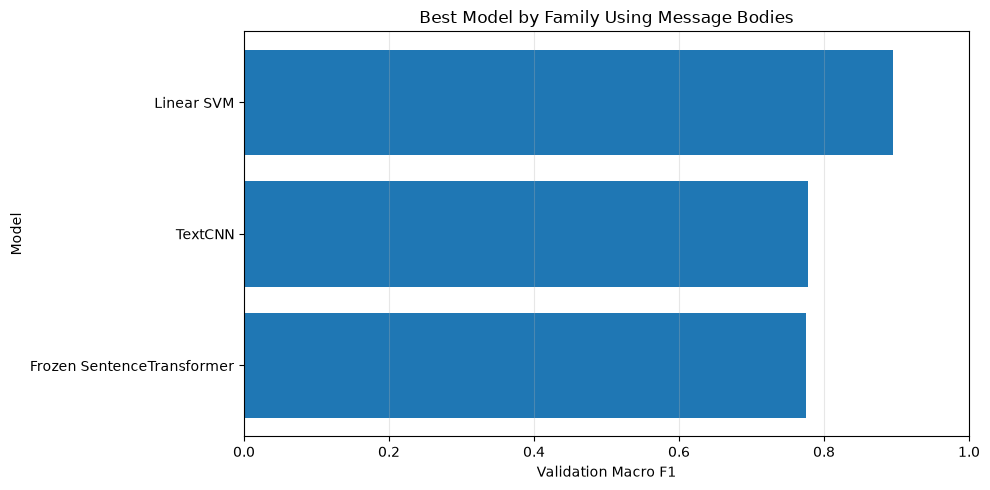

In [8]:
matched_plot = best_message_body_by_family.sort_values("macro_f1")

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    matched_plot["model"],
    matched_plot["macro_f1"],
)

ax.set_title("Best Model by Family Using Message Bodies")
ax.set_xlabel("Validation Macro F1")
ax.set_ylabel("Model")
ax.set_xlim(0, 1)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpreting the Message-Body Comparison

Restricting the comparison to message bodies provides a more balanced view of the different model families.

The best classical configuration using message bodies achieves a macro F1 of approximately 0.8947. This remains substantially higher than the scores obtained by the neural-network and transformer experiments.

TextCNN achieves approximately 0.7774 macro F1, while the frozen SentenceTransformer embedding approach achieves approximately 0.7755. DistilBERT achieves approximately 0.7709, and the BiLSTM records approximately 0.5465.

These results indicate that the classical approach remains highly competitive even when the input representation is held constant.

The relatively small differences between TextCNN, frozen embeddings, and DistilBERT should not be interpreted as evidence of a meaningful performance difference without repeated experiments or statistical testing.

The comparison also demonstrates that using a more computationally complex architecture does not automatically produce better classification performance. The effectiveness of an approach depends on the dataset, representation, model configuration, and available training resources.

## 6.6 Performance Across Model Families

The following visualisation provides an overview of the strongest validation result obtained by each model family.

For classical machine learning, the best configuration is selected from all twelve experiments. For neural networks and transformers, the strongest result within each family is selected.

This comparison is useful for identifying the strongest available approach in each family, although the representation differences discussed earlier must remain part of the interpretation.

In [9]:
best_by_family = (
    comparison_df
    .sort_values("macro_f1", ascending=False)
    .groupby("model_family", as_index=False)
    .first()
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(
    best_by_family[
        [
            "model_family",
            "model",
            "classifier",
            "feature_type",
            "representation",
            "accuracy",
            "macro_f1",
            "weighted_f1",
        ]
    ]
)

fig, ax = plt.subplots(figsize=(9, 5))

family_plot = best_by_family.sort_values("macro_f1")

ax.barh(
    family_plot["model_family"],
    family_plot["macro_f1"],
)

ax.set_title("Best Validation Macro F1 by Model Family")
ax.set_xlabel("Validation Macro F1")
ax.set_ylabel("Model Family")
ax.set_xlim(0, 1)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

KeyError: "['classifier'] not in index"

### Interpreting Model-Family Performance

The comparison shows that classical machine learning achieves the strongest validation performance among the evaluated model families.

This finding is important because it provides evidence against assuming that neural networks or transformers will necessarily outperform conventional machine-learning algorithms on this dataset.

The result should not be interpreted as a universal statement about the relative effectiveness of these approaches. It applies to the configurations, dataset, representations, and computational conditions evaluated in this project.

The classical models also provide a useful performance baseline against which the additional computational requirements of the more complex approaches can be assessed.

## 6.7 Per-Class Performance

Aggregate metrics provide a useful summary, but they can conceal differences in performance across individual categories.

The following analysis examines the per-class precision, recall, and F1 scores of the strongest overall validation configuration.

This allows us to identify categories that are classified reliably and categories that remain more difficult for the selected model.

In [10]:
best_run = max(
    runs,
    key=lambda run: run["macro_f1"],
)

best_run_id = best_run["run_id"]

print(f"Best configuration: {best_run['model']}")
print(f"Run ID: {best_run_id}")
print(f"Representation: {best_run['representation']}")
print(f"Validation macro F1: {best_run['macro_f1']:.4f}")

assert "per_class" in best_run, (
    "Per-class metrics are missing from the best experiment record."
)

per_class_df = (
    pd.DataFrame.from_dict(
        best_run["per_class"],
        orient="index",
    )
    .rename_axis("class")
    .reset_index()
)

per_class_df = per_class_df.sort_values(
    "f1_score",
    ascending=False,
).reset_index(drop=True)

display(per_class_df)

Best configuration: Linear SVM
Run ID: linear_svm__tfidf__full_message
Representation: full_message
Validation macro F1: 0.9138


AssertionError: Per-class metrics are missing from the best experiment record.

In [11]:
per_class_plot = per_class_df.sort_values("f1_score")

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    per_class_plot["class"],
    per_class_plot["f1_score"],
)

ax.set_title(
    f"Per-Class F1 Scores: {best_run['model']}"
)
ax.set_xlabel("F1 Score")
ax.set_ylabel("Newsgroup Category")
ax.set_xlim(0, 1)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

NameError: name 'per_class_df' is not defined

### Interpreting Per-Class Performance

The per-class results provide a more detailed assessment of the strongest validation configuration.

Differences between category-level F1 scores indicate that the model does not perform equally well across all twenty newsgroups. Some categories are easier to distinguish using their available vocabulary and message content, while others may share terminology or discuss related subjects.

The results should be interpreted alongside the class support values. A category with relatively few validation examples may have a less stable performance estimate than a category with substantially more examples.

These findings help identify categories that deserve additional attention during the subsequent error-analysis stage.

## 6.8 Confusion Matrix Analysis

A confusion matrix provides a more detailed view of the classification errors made by the strongest overall configuration.

The diagonal represents correctly classified documents, while the off-diagonal entries show documents assigned to an incorrect category.

Examining these patterns helps identify which categories are most frequently confused with one another.

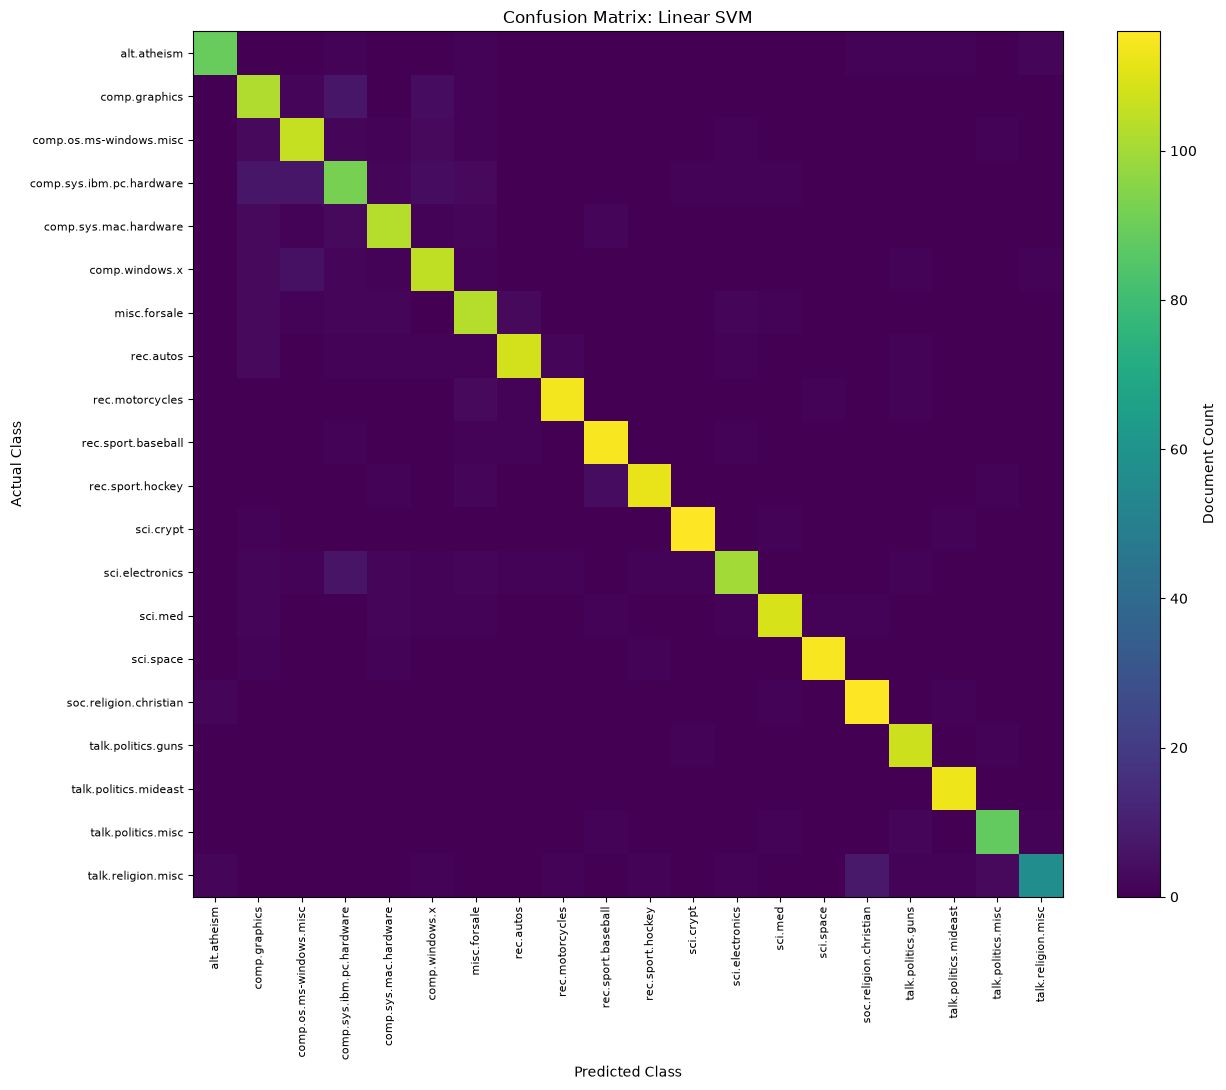

In [12]:
confusion_matrix = np.asarray(
    best_run["confusion_matrix"],
)

class_labels = best_run["class_labels"]

assert confusion_matrix.shape == (
    len(class_labels),
    len(class_labels),
)

fig, ax = plt.subplots(figsize=(13, 11))

image = ax.imshow(
    confusion_matrix,
    interpolation="nearest",
    aspect="auto",
)

ax.set_title(
    f"Confusion Matrix: {best_run['model']}"
)
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

ax.set_xticks(range(len(class_labels)))
ax.set_yticks(range(len(class_labels)))

ax.set_xticklabels(
    class_labels,
    rotation=90,
    fontsize=8,
)

ax.set_yticklabels(
    class_labels,
    fontsize=8,
)

fig.colorbar(image, ax=ax, label="Document Count")

plt.tight_layout()
plt.show()

In [13]:
off_diagonal = confusion_matrix.copy()
np.fill_diagonal(off_diagonal, 0)

error_pairs = (
    pd.DataFrame(
        off_diagonal,
        index=class_labels,
        columns=class_labels,
    )
    .rename_axis("actual_class")
    .reset_index()
    .melt(
        id_vars="actual_class",
        var_name="predicted_class",
        value_name="document_count",
    )
    .query("document_count > 0")
    .sort_values(
        "document_count",
        ascending=False,
    )
    .head(15)
    .reset_index(drop=True)
)

display(error_pairs)

,actual_class,predicted_class,document_count
0,talk.religion.misc,soc.religion.christian,8
1,comp.sys.ibm.pc.hardware,comp.graphics,7
2,comp.graphics,comp.sys.ibm.pc.hardware,7
3,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,7
4,sci.electronics,comp.sys.ibm.pc.hardware,6
5,comp.windows.x,comp.os.ms-windows.misc,5
6,comp.sys.ibm.pc.hardware,comp.windows.x,4
7,comp.graphics,comp.windows.x,4
8,rec.sport.hockey,rec.sport.baseball,4
9,comp.os.ms-windows.misc,comp.graphics,3


### Interpreting the Confusion Matrix

The confusion matrix makes it possible to distinguish overall classification performance from the specific errors that contribute to it.

Misclassifications between related newsgroups may reflect overlapping terminology, shared subject matter, or messages that discuss multiple topics. However, the confusion matrix alone cannot establish the cause of an individual error.

The most frequent incorrect class assignments provide useful starting points for the dedicated error-analysis notebook. That analysis will examine individual documents to determine whether errors arise from ambiguous content, quoted material, overlapping topics, or other characteristics of the dataset.

The confusion analysis therefore complements the aggregate metrics by identifying where the selected model's predictions require closer examination.

## 6.9 Training and Inference Efficiency

Predictive performance is only one aspect of model selection. Computational requirements also matter, particularly given the CPU-only environment used for these experiments.

This section compares the recorded training-related time and end-to-end validation inference time.

The timing measurements require some care when interpreting the results. The classical pipeline includes vectorisation during prediction, whereas the neural-network prediction measurement operates on already encoded sequences. The transformer measurements include their respective tokenisation or embedding-generation stages.

The recorded training-related times also differ in scope. For example, the frozen embedding approach includes training embedding generation in addition to classifier fitting, while the DistilBERT measurement records fine-tuning time.

The following comparisons should therefore be interpreted as measurements of the implemented experimental workflows, not perfectly equivalent measurements of isolated model computation.

In [14]:
efficiency_columns = [
    column
    for column in [
        "model",
        "model_family",
        "representation",
        "macro_f1",
        "training_related_seconds",
        "end_to_end_inference_seconds",
        "end_to_end_latency_ms_per_document",
        "end_to_end_throughput_documents_per_second",
        "training_cost_scope",
        "inference_cost_scope",
    ]
    if column in comparison_df.columns
]

efficiency_df = (
    comparison_df
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(efficiency_df[efficiency_columns])

,model,model_family,representation,macro_f1,training_related_seconds,end_to_end_inference_seconds,end_to_end_latency_ms_per_document,end_to_end_throughput_documents_per_second,training_cost_scope,inference_cost_scope
0,Linear SVM,Classical ML,full_message,0.9138,16.2725,1.4973,0.6616,1511.4314,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
1,Linear SVM,Classical ML,message_body,0.8947,23.6573,1.5877,0.7016,1425.3327,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
2,Logistic Regression,Classical ML,full_message,0.8795,42.9605,1.2576,0.5557,1799.5074,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
3,Linear SVM,Classical ML,full_message,0.8789,42.7064,1.4368,0.6349,1575.0673,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
4,Logistic Regression,Classical ML,full_message,0.8731,109.5000,1.9411,0.8578,1165.8258,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
5,Logistic Regression,Classical ML,message_body,0.8550,60.8556,1.4454,0.6387,1565.6727,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
6,Multinomial Naive Bayes,Classical ML,full_message,0.8293,10.6517,1.8191,0.8039,1243.9992,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
7,Multinomial Naive Bayes,Classical ML,full_message,0.8272,12.2079,0.9043,0.3996,2502.3546,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
8,Logistic Regression,Classical ML,message_body,0.8219,149.1217,1.7969,0.7940,1259.4128,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
9,Multinomial Naive Bayes,Classical ML,message_body,0.8053,12.7697,1.6243,0.7178,1393.2300,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...


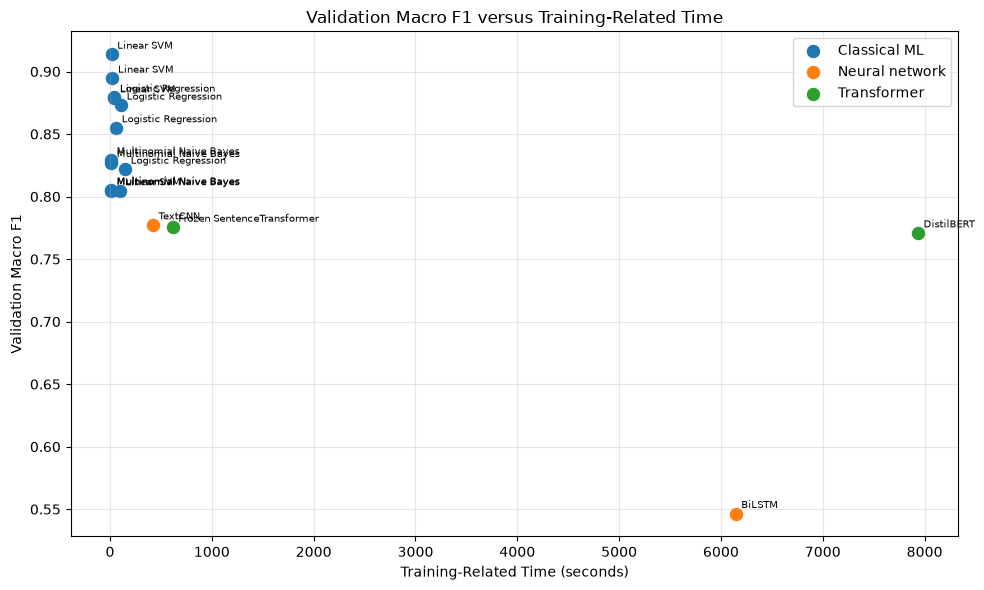

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

for family, group in efficiency_df.groupby("model_family"):
    ax.scatter(
        group["training_related_seconds"],
        group["macro_f1"],
        label=family,
        s=75,
    )

for _, row in efficiency_df.iterrows():
    ax.annotate(
        row["model"],
        (
            row["training_related_seconds"],
            row["macro_f1"],
        ),
        fontsize=7,
        xytext=(4, 4),
        textcoords="offset points",
    )

ax.set_title("Validation Macro F1 versus Training-Related Time")
ax.set_xlabel("Training-Related Time (seconds)")
ax.set_ylabel("Validation Macro F1")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Interpreting Training Efficiency

The training-time comparison illustrates the computational differences between the evaluated approaches.

The TextCNN completed training in approximately seven minutes, while the BiLSTM required approximately 102 minutes. Despite its considerably longer training time, the BiLSTM achieved a lower validation macro F1 than TextCNN.

DistilBERT fine-tuning required approximately two hours and twelve minutes. Its validation macro F1 was lower than that of the strongest classical configuration and TextCNN.

These results demonstrate that increased computational cost did not translate into improved validation performance in the experiments conducted.

However, the timing measurements should not be treated as perfectly standardised benchmarks. The models have different training procedures and the recorded timing scopes are not identical. They are most useful for understanding the practical resource requirements of the implemented experiments.

In [16]:
inference_columns = [
    column
    for column in [
        "model",
        "model_family",
        "macro_f1",
        "end_to_end_inference_seconds",
        "end_to_end_latency_ms_per_document",
        "end_to_end_throughput_documents_per_second",
        "inference_cost_scope",
    ]
    if column in comparison_df.columns
]

display(
    comparison_df[
        inference_columns
    ].sort_values(
        "end_to_end_inference_seconds",
        ascending=True,
    )
)

,model,model_family,macro_f1,end_to_end_inference_seconds,end_to_end_latency_ms_per_document,end_to_end_throughput_documents_per_second,inference_cost_scope
7,Multinomial Naive Bayes,Classical ML,0.8272,0.9043,0.3996,2502.3546,Vectorizer transformation and classifier predi...
12,TextCNN,Neural network,0.7774,0.9310,0.4114,2430.6530,Model prediction on encoded sequences
10,Multinomial Naive Bayes,Classical ML,0.8046,1.1184,0.4942,2023.4066,Vectorizer transformation and classifier predi...
2,Logistic Regression,Classical ML,0.8795,1.2576,0.5557,1799.5074,Vectorizer transformation and classifier predi...
11,Linear SVM,Classical ML,0.8046,1.3559,0.5992,1668.9991,Vectorizer transformation and classifier predi...
3,Linear SVM,Classical ML,0.8789,1.4368,0.6349,1575.0673,Vectorizer transformation and classifier predi...
5,Logistic Regression,Classical ML,0.8550,1.4454,0.6387,1565.6727,Vectorizer transformation and classifier predi...
0,Linear SVM,Classical ML,0.9138,1.4973,0.6616,1511.4314,Vectorizer transformation and classifier predi...
1,Linear SVM,Classical ML,0.8947,1.5877,0.7016,1425.3327,Vectorizer transformation and classifier predi...
9,Multinomial Naive Bayes,Classical ML,0.8053,1.6243,0.7178,1393.2300,Vectorizer transformation and classifier predi...


### Interpreting Inference Efficiency

Inference time and throughput provide additional information about the practical usability of each approach.

A shorter inference time indicates that a model can process the validation documents more quickly under the measured conditions. Throughput expresses the number of documents processed per second, while latency expresses the average time required per document.

These values must be interpreted in light of their measurement scopes. In particular, transformer tokenisation and frozen embedding generation contribute to end-to-end inference time, whereas the neural-network measurements operate on prepared input sequences.

The results therefore describe the measured inference workflows rather than providing a perfectly controlled hardware benchmark of the model architectures alone.

## 6.10 Model Artifact Size and Memory Usage

The size of a saved model artifact is relevant when considering storage requirements and deployment.

However, the artifact-size measurements do not cover identical components for every model. Classical artifacts contain the fitted vectorisation and classification pipeline. Neural-network artifacts contain their saved model parameters and vocabulary. The DistilBERT artifact measurement includes the fine-tuned model and tokenizer, whereas the frozen embedding experiment records the classifier artifact without including the pretrained SentenceTransformer encoder.

Memory measurements also have different monitoring scopes. They should not be treated as directly equivalent estimates of peak memory consumption across all model families.

The following analysis presents the available measurements together with their recorded scope.

In [17]:
artifact_columns = [
    column
    for column in [
        "model",
        "model_family",
        "artifact_size_bytes",
        "artifact_size_scope",
    ]
    if column in comparison_df.columns
]

artifact_df = comparison_df[artifact_columns].copy()

if "artifact_size_bytes" in artifact_df.columns:
    artifact_df["artifact_size_mb"] = (
        artifact_df["artifact_size_bytes"] / (1024 ** 2)
    )

    artifact_df = artifact_df.sort_values(
        "artifact_size_mb",
        ascending=False,
    )

display(artifact_df)

,model,model_family,artifact_size_bytes,artifact_size_scope,artifact_size_mb
14,DistilBERT,Transformer,268606876,Fine-tuned model and tokenizer,256.1635
6,Multinomial Naive Bayes,Classical ML,35902689,Fitted scikit-learn pipeline,34.2395
9,Multinomial Naive Bayes,Classical ML,35900497,Fitted scikit-learn pipeline,34.2374
7,Multinomial Naive Bayes,Classical ML,35102605,Fitted scikit-learn pipeline,33.4765
10,Multinomial Naive Bayes,Classical ML,35100413,Fitted scikit-learn pipeline,33.4744
2,Logistic Regression,Classical ML,19902636,Fitted scikit-learn pipeline,18.9806
0,Linear SVM,Classical ML,19902488,Fitted scikit-learn pipeline,18.9805
5,Logistic Regression,Classical ML,19900444,Fitted scikit-learn pipeline,18.9785
1,Linear SVM,Classical ML,19900296,Fitted scikit-learn pipeline,18.9784
4,Logistic Regression,Classical ML,19102536,Fitted scikit-learn pipeline,18.2176


In [18]:
memory_columns = [
    column
    for column in comparison_df.columns
    if "memory" in column.lower()
    or "rss" in column.lower()
]

if memory_columns:
    display(
        comparison_df[
            [
                column
                for column in [
                    "model",
                    "model_family",
                    *memory_columns,
                ]
                if column in comparison_df.columns
            ]
        ]
    )
else:
    print(
        "No memory measurements are available in the consolidated "
        "comparison records."
    )

,model,model_family,peak_sampled_rss_bytes
0,Linear SVM,Classical ML,NaN
1,Linear SVM,Classical ML,NaN
2,Logistic Regression,Classical ML,NaN
3,Linear SVM,Classical ML,NaN
4,Logistic Regression,Classical ML,NaN
5,Logistic Regression,Classical ML,NaN
6,Multinomial Naive Bayes,Classical ML,NaN
7,Multinomial Naive Bayes,Classical ML,NaN
8,Logistic Regression,Classical ML,NaN
9,Multinomial Naive Bayes,Classical ML,NaN


### Interpreting Artifact Size and Memory Measurements

Artifact size provides an indication of the storage requirements associated with the saved model components.

The measurements must not be interpreted as directly equivalent deployment footprints because some experiments include additional components that others exclude. The frozen embedding classifier artifact, for example, does not include the pretrained sentence encoder required for inference.

Similarly, memory measurements depend on when monitoring begins and which parts of the workflow are included. The DistilBERT and frozen embedding experiments do not have identical monitoring scopes.

These limitations are important when considering deployment requirements. A more detailed resource comparison would require a standardised measurement procedure that includes all components necessary to load and serve each model.

## 6.11 Overall Findings and Model Selection

The preceding analyses provide evidence for comparing the predictive performance and computational requirements of the evaluated approaches.

The strongest overall validation configuration is the Linear SVM with TF-IDF features and the complete-message representation. It achieves a macro F1 of approximately 0.9138.

The strongest classical message-body configuration also performs well, achieving approximately 0.8947 macro F1. This is important because it demonstrates that the classical approach remains competitive even when compared using the same broad text representation as the neural-network and transformer experiments.

TextCNN provides the strongest neural-network result, while the frozen SentenceTransformer approach and DistilBERT achieve similar validation performance. The BiLSTM records the lowest macro F1 among the evaluated model configurations and requires substantially more training time than TextCNN.

The results suggest that model complexity and computational cost should be justified by measurable improvements in predictive performance rather than assumed to produce better results.